# T04 · Imbalanced Classification (Undersampling · Oversampling · SMOTE · Cost-sensitive · Threshold)

**ใช้เมื่อโจทย์ถาม:** คลาสไม่สมดุล · ทำไม accuracy หลอก · random under/oversampling · **SMOTE** · SMOTE ต้องทำเฉพาะ training ·
เทียบก่อน/หลัง resampling · class_weight / cost-sensitive · เลือก metric (recall / precision / F1 / PR-AUC) · ปรับ threshold

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — สำคัญที่สุด: `TARGET`, `POS_LABEL` (= คลาสส่วนน้อยที่สนใจ) |
| 2 | Run All · ตารางหลักอยู่ §4 · ตาราง threshold อยู่ §7 |

> 🔑 กฎทอง: **resample เฉพาะ training (ใน fold) — ห้ามแตะ test** → ใช้ `imblearn.pipeline.Pipeline` แล้ว CV

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p3_breast_cancer_imbalanced.csv"
TARGET    = "diagnosis"
POS_LABEL = "malignant"     # คลาสส่วนน้อย/คลาสที่สนใจ (= 1)
ID_COL    = None
DROP_COLS = []
SCALE     = "standard"
MODEL_NAME = "LogReg"       # โมเดลหลักที่จะลอง resampling: "LogReg" | "KNN" | "Tree" | "RF"
PRIMARY_METRIC = "f1"       # metric ที่ใช้เลือก: "f1" | "recall" | "precision"
SMOTE_K   = 5               # k_neighbors ของ SMOTE
EVAL_MODE = "cv"            # "cv" = stratified k-fold · "holdout" = แบ่ง train/test
N_FOLDS, TEST_SIZE, SEED = 5, 0.2, 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred)}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()
    return cm


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 โหลด + ดูความไม่สมดุล

โหลด ../practice/data/p3_breast_cancer_imbalanced.csv → 397 แถว × 11 คอลัมน์
shape: (397, 11) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
radius,float64,0,0.0000,317,13.6900
texture,float64,0,0.0000,345,16.0700
perimeter,float64,0,0.0000,375,87.8400
area,float64,0,0.0000,379,579.1000
smoothness,float64,0,0.0000,356,0.0830
compactness,float64,0,0.0000,383,0.0637
concavity,float64,0,0.0000,372,0.0256
concave_points,float64,0,0.0000,377,0.0203
symmetry,float64,0,0.0000,326,0.1872
fractal_dimension,float64,0,0.0000,359,0.0567


การกระจายของ target 'diagnosis':


,count,ratio
diagnosis,,
benign,357,0.8992
malignant,40,0.1008


X: (397, 10) | y = 'diagnosis' → 1 = 'malignant' (positive), 0 = 'benign' | ตัดคอลัมน์: []
✍️ คลาสส่วนน้อย (1 = malignant) มี 40 แถว (10.1%) · คลาสส่วนใหญ่ 357 แถว → imbalance ratio 8.93 : 1


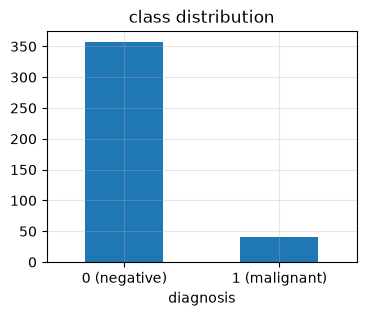

In [3]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

df = load_data(DATA_PATH)
check(df, TARGET)
X, y = make_xy(df)
counts = y.value_counts()
ratio = counts.max() / counts.min()
print(f"✍️ คลาสส่วนน้อย (1 = {POS_LABEL}) มี {counts.get(1, 0)} แถว ({y.mean():.1%}) · คลาสส่วนใหญ่ {counts.get(0, 0)} แถว → imbalance ratio {ratio:.2f} : 1")
counts.rename({0: "0 (negative)", 1: f"1 ({POS_LABEL})"}).plot(kind="bar", figsize=(4, 3), title="class distribution", rot=0); plt.show()

## §2 ทำไม accuracy หลอก — majority baseline
โมเดลที่ทายคลาสใหญ่ทุกแถวได้ accuracy = สัดส่วนคลาสใหญ่ แต่ **recall/F1 ของคลาสส่วนน้อย = 0**

In [4]:
cv = get_cv()
base = evaluate("Majority baseline", DummyClassifier(strategy="most_frequent"), X, y, cv)
print(f"✍️ majority baseline ได้ accuracy {base['accuracy']:.4f} แต่ recall {base['recall']:.4f} และ F1 {base['f1']:.4f} → "
      "accuracy สูงแต่หาคลาสที่สนใจไม่เจอเลย จึงต้องใช้ recall / precision / F1 ของคลาสส่วนน้อย")

✍️ majority baseline ได้ accuracy 0.8992 แต่ recall 0.0000 และ F1 0.0000 → accuracy สูงแต่หาคลาสที่สนใจไม่เจอเลย จึงต้องใช้ recall / precision / F1 ของคลาสส่วนน้อย


## §3 Resampling บน training set (สาธิต: จำนวนก่อน/หลัง — test ไม่ถูกแตะ)
| วิธี | ทำอะไร | ข้อดี / ข้อเสีย |
|---|---|---|
| Random **Under**sampling | ลบคลาสใหญ่ให้เท่าคลาสเล็ก | เร็ว · ทิ้งข้อมูล |
| Random **Over**sampling | copy คลาสเล็กซ้ำ | ไม่เสียข้อมูล · overfit จุดซ้ำ |
| **SMOTE** | สร้างจุดใหม่บนเส้นระหว่างจุดคลาสเล็กกับ k เพื่อนบ้าน: $x_{new}=x+\lambda(x_{nn}-x)$ | ไม่ซ้ำ · อาจสร้าง noise ที่ขอบคลาส |
| class_weight="balanced" | ให้น้ำหนัก error คลาสเล็กมากขึ้น (cost-sensitive) | ไม่เปลี่ยนข้อมูล |

diagnosis,class 0,class 1 (malignant)
original train,285,32
RandomUnderSampler,32,32
RandomOverSampler,285,285
SMOTE,285,285
test (ไม่แตะ),72,8


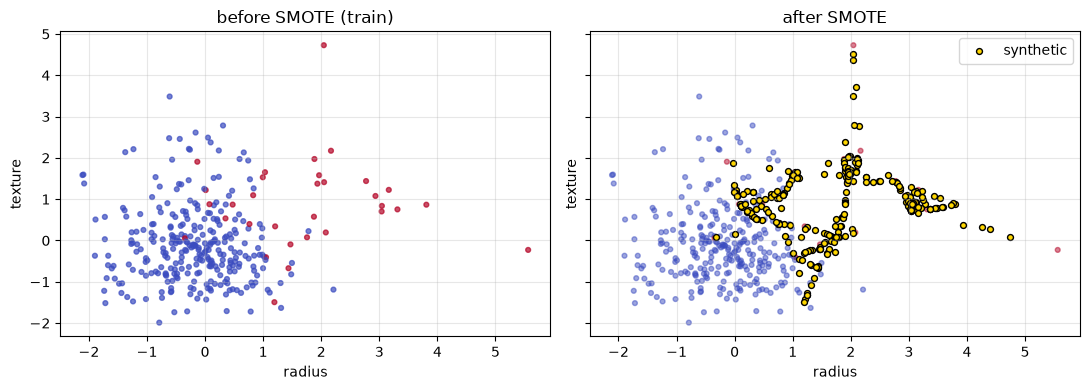

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
prep = build_prep(X_train).fit(X_train)
Xtr = prep.transform(X_train)
show = {"original train": y_train.value_counts().sort_index()}
for name, s in [("RandomUnderSampler", RandomUnderSampler(random_state=SEED)),
                ("RandomOverSampler", RandomOverSampler(random_state=SEED)),
                ("SMOTE", SMOTE(k_neighbors=SMOTE_K, random_state=SEED))]:
    _, yr = s.fit_resample(Xtr, y_train)
    show[name] = pd.Series(yr).value_counts().sort_index()
show["test (ไม่แตะ)"] = y_test.value_counts().sort_index()
display(pd.DataFrame(show).T.rename(columns={0: "class 0", 1: f"class 1 ({POS_LABEL})"}))

# ภาพ SMOTE บน 2 feature แรก (หลัง scale)
Xs, ys = SMOTE(k_neighbors=SMOTE_K, random_state=SEED).fit_resample(Xtr[:, :2], y_train)
n0 = len(Xtr)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
ax[0].scatter(Xtr[:, 0], Xtr[:, 1], c=y_train, cmap="coolwarm", s=12, alpha=.7); ax[0].set_title("before SMOTE (train)")
ax[1].scatter(Xs[:n0, 0], Xs[:n0, 1], c=ys[:n0], cmap="coolwarm", s=12, alpha=.5)
ax[1].scatter(Xs[n0:, 0], Xs[n0:, 1], c="gold", edgecolor="k", s=18, label="synthetic"); ax[1].legend(); ax[1].set_title("after SMOTE")
for a in ax: a.set(xlabel=prep.get_feature_names_out()[0], ylabel=prep.get_feature_names_out()[1])
plt.tight_layout(); plt.show()

## §4 เปรียบเทียบ: ไม่ทำอะไร vs Under vs Over vs SMOTE vs class_weight ⭐
resampler อยู่ **ใน** `ImbPipeline` → ใน CV จะ resample เฉพาะ training fold · validation fold เป็นข้อมูลจริงเสมอ

,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.8992,0.0000,0.0000,0.0000,0.0000
1,LogReg + No resampling,,0.9647,0.9179,0.7250,0.7998,0.0730
2,LogReg + RandomUnderSampler,,0.9118,0.5400,0.9000,0.6724,0.0368
3,LogReg + RandomOverSampler,,0.9244,0.6173,0.8750,0.7027,0.0230
4,LogReg + SMOTE,,0.9345,0.6531,0.8750,0.7299,0.0335
5,LogReg + class_weight=balanced,,0.9269,0.6239,0.8750,0.7085,0.0157


✍️ โมเดลที่ดีที่สุดตาม f1 คือ LogReg + No resampling ได้ f1 = 0.7998 เทียบกับ baseline (Majority baseline) ที่ได้ 0.0000 ต่างกัน +0.7998 (baseline accuracy = 0.8992 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)


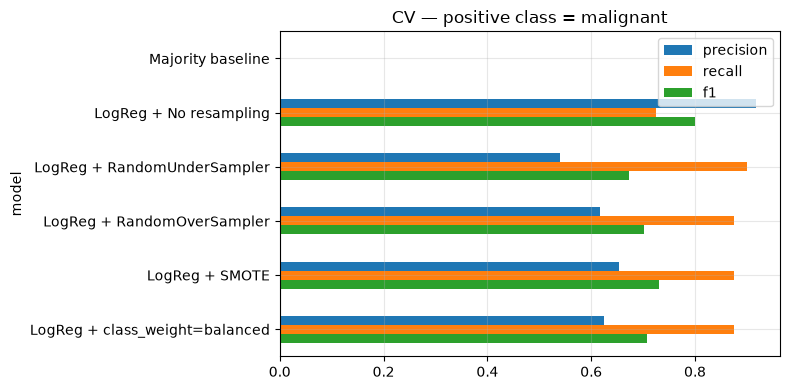

In [6]:
def base_model(balanced=False):
    cw = "balanced" if balanced else None
    return {"LogReg": LogisticRegression(max_iter=5000, class_weight=cw),
            "KNN": KNeighborsClassifier(n_neighbors=5),
            "Tree": DecisionTreeClassifier(max_depth=5, random_state=SEED, class_weight=cw),
            "RF": RandomForestClassifier(n_estimators=200, random_state=SEED, class_weight=cw)}[MODEL_NAME]

def imb_pipe(sampler=None, balanced=False):
    steps = [("prep", build_prep(X))]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", base_model(balanced)))
    return ImbPipeline(steps)

variants = {"No resampling": imb_pipe(),
            "RandomUnderSampler": imb_pipe(RandomUnderSampler(random_state=SEED)),
            "RandomOverSampler": imb_pipe(RandomOverSampler(random_state=SEED)),
            "SMOTE": imb_pipe(SMOTE(k_neighbors=SMOTE_K, random_state=SEED))}
if MODEL_NAME != "KNN":
    variants["class_weight=balanced"] = imb_pipe(balanced=True)

rows = [base]
for name, pipe in variants.items():
    if EVAL_MODE == "cv":
        rows.append(evaluate(f"{MODEL_NAME} + {name}", pipe, X, y, cv))
    else:
        rows.append(evaluate_holdout(f"{MODEL_NAME} + {name}", pipe, X_train, y_train, X_test, y_test))
imb = results_table(rows)
say_compare(imb, PRIMARY_METRIC, "Majority baseline")
imb.set_index("model")[["precision", "recall", "f1"]].plot(kind="barh", figsize=(8, 4), title=f"{EVAL_MODE.upper()} — positive class = {POS_LABEL}")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

**✍️ คำตอบ §4:** ไม่ resample ได้ recall … F1 … · SMOTE ทำให้ recall เพิ่มเป็น … (precision เปลี่ยนเป็น …) เพราะโมเดลเห็นคลาสส่วนน้อยมากขึ้น · undersampling … · เลือก … เพราะ …

## §5 Confusion matrix: ไม่ resample vs SMOTE (cross_val_predict — ทุกแถวถูกทำนายตอนอยู่ใน validation fold)

===== LogReg + No resampling =====


,pred 0,pred 1
actual 0,354,3
actual 1,11,29


TN=354  FP=3  FN=11  TP=29
              precision    recall  f1-score   support

           0     0.9699    0.9916    0.9806       357
           1     0.9062    0.7250    0.8056        40

    accuracy                         0.9647       397
   macro avg     0.9381    0.8583    0.8931       397
weighted avg     0.9635    0.9647    0.9630       397



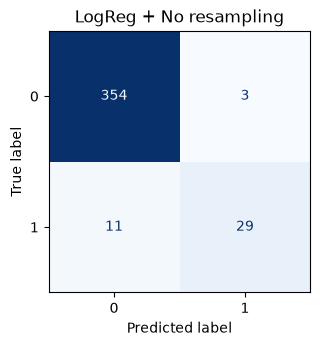

===== LogReg + SMOTE =====


,pred 0,pred 1
actual 0,336,21
actual 1,5,35


TN=336  FP=21  FN=5  TP=35
              precision    recall  f1-score   support

           0     0.9853    0.9412    0.9628       357
           1     0.6250    0.8750    0.7292        40

    accuracy                         0.9345       397
   macro avg     0.8052    0.9081    0.8460       397
weighted avg     0.9490    0.9345    0.9392       397



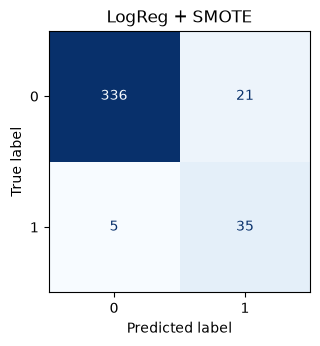

In [7]:
for name in ["No resampling", "SMOTE"]:
    pred = cross_val_predict(variants[name], X, y, cv=cv)
    print(f"===== {MODEL_NAME} + {name} =====")
    show_cm(y, pred, title=f"{MODEL_NAME} + {name}")

**✍️ คำตอบ §5:** SMOTE ลด FN จาก … เหลือ … (หาคลาส {POS_LABEL} เจอเพิ่ม) แต่ FP เพิ่มจาก … เป็น … → trade-off recall ↑ precision ↓

## §6 ❌ วิธีผิด: SMOTE ทั้งตารางก่อน CV (data leakage) — ไว้ตอบคำถาม "ทำไมห้าม"
จุดสังเคราะห์ถูกสร้างจากจุดที่อยู่ใน validation fold → validation ไม่ใช่ข้อมูลจริง → คะแนนสูงเกินจริง

In [8]:
Xall = build_prep(X).fit_transform(X)
Xw, yw = SMOTE(k_neighbors=SMOTE_K, random_state=SEED).fit_resample(Xall, y)
wrong = evaluate("❌ SMOTE ก่อน CV (leak)", base_model(), Xw, yw, cv)
right = [r for r in rows if r["model"].endswith("+ SMOTE")][0]
results_table([right, wrong])
print(f"✍️ SMOTE ก่อน CV ได้ F1 {wrong['f1']:.4f} สูงกว่าวิธีถูก ({right['f1']:.4f}) เพราะ validation มีจุดสังเคราะห์ที่ลอกมาจาก training → ประเมินสูงเกินจริง")

,model,settings,accuracy,precision,recall,f1,f1_std
0,LogReg + SMOTE,,0.9345,0.6531,0.8750,0.7299,0.0335
1,❌ SMOTE ก่อน CV (leak),,0.9356,0.9336,0.9384,0.9358,0.0160


✍️ SMOTE ก่อน CV ได้ F1 0.9358 สูงกว่าวิธีถูก (0.7299) เพราะ validation มีจุดสังเคราะห์ที่ลอกมาจาก training → ประเมินสูงเกินจริง


## §7 ปรับ threshold (อีกทางแก้ imbalance — ไม่ต้อง resample)
`predict()` ตัดที่ 0.5 · ลด threshold → recall ↑ precision ↓ · เลือก threshold ตามต้นทุน FN vs FP

,threshold,TP,FP,FN,TN,accuracy,precision,recall,f1
0,0.1000,37,32,3,325,0.9118,0.5362,0.9250,0.6789
1,0.2000,34,12,6,345,0.9547,0.7391,0.8500,0.7907
2,0.3000,30,6,10,351,0.9597,0.8333,0.7500,0.7895
3,0.4000,30,4,10,353,0.9647,0.8824,0.7500,0.8108
4,0.5000,29,3,11,354,0.9647,0.9062,0.7250,0.8056
5,0.6000,28,2,12,355,0.9647,0.9333,0.7000,0.8000
6,0.7000,27,2,13,355,0.9622,0.9310,0.6750,0.7826


✍️ threshold ที่ f1 สูงสุด = 0.4 (f1 0.8108, recall 0.7500, precision 0.8824)


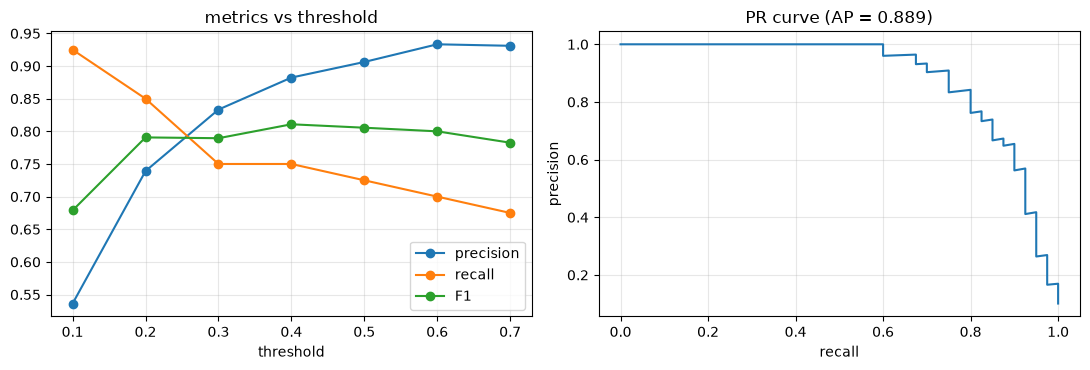

ROC-AUC = 0.9675 | PR-AUC (average precision) = 0.8894  ← PR-AUC เหมาะกับ imbalanced มากกว่า


In [9]:
THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]      # ✏️
proba = cross_val_predict(variants["No resampling"], X, y, cv=cv, method="predict_proba")[:, 1]
trows = []
for t in THRESHOLDS:
    p = (proba >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    trows.append({"threshold": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn, "accuracy": accuracy_score(y, p),
                  "precision": precision_score(y, p, zero_division=0), "recall": recall_score(y, p), "f1": f1_score(y, p)})
tt = results_table(trows)
best_t = tt.loc[tt[PRIMARY_METRIC].idxmax()]
print(f"✍️ threshold ที่ {PRIMARY_METRIC} สูงสุด = {best_t['threshold']} ({PRIMARY_METRIC} {best_t[PRIMARY_METRIC]:.4f}, recall {best_t['recall']:.4f}, precision {best_t['precision']:.4f})")
prec, rec, thr = precision_recall_curve(y, proba)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tt["threshold"], tt["precision"], "o-", label="precision"); ax[0].plot(tt["threshold"], tt["recall"], "o-", label="recall")
ax[0].plot(tt["threshold"], tt["f1"], "o-", label="F1"); ax[0].set(xlabel="threshold", title="metrics vs threshold"); ax[0].legend()
ax[1].plot(rec, prec); ax[1].set(xlabel="recall", ylabel="precision", title=f"PR curve (AP = {average_precision_score(y, proba):.3f})")
plt.tight_layout(); plt.show()
print(f"ROC-AUC = {roc_auc_score(y, proba):.4f} | PR-AUC (average precision) = {average_precision_score(y, proba):.4f}  ← PR-AUC เหมาะกับ imbalanced มากกว่า")

## §8 เลือก metric ให้เหมาะกับปัญหา (copy ไปตอบ)
| สถานการณ์ | metric | เหตุผล |
|---|---|---|
| พลาดคลาสสนใจแพง (โรค, ฉ้อโกง, churn) | **recall** | ลด FN |
| เตือนผิดแพง (spam, ส่งโปรโมชันมีต้นทุน) | **precision** | ลด FP |
| ต้องสมดุลทั้งสอง | **F1** | harmonic mean ของ P และ R |
| ข้อมูลสมดุล ต้นทุนเท่ากัน | accuracy | — |
| เทียบโมเดลโดยไม่ผูก threshold (imbalanced) | PR-AUC | ไม่ถูกคลาสใหญ่ครอบงำเหมือน ROC-AUC |

**✍️ คำตอบ:** ข้อมูลนี้คลาส {POS_LABEL} มีแค่ …% · accuracy ของ baseline … จึงหลอก · เลือก … เพราะการพลาด … (FN/FP) เสียหายกว่า · โมเดลสุดท้าย = … ได้ … = …